### SmallTalk 2: LoRA SFT and DPO
Fine-tunes one small model in two steps:
1. **LoRA SFT** (QLoRA, 4-bit base): learn to write QMSum-style summaries from retrieved chunks
2. **DPO**: the SFT model writes 4 summaries per question, each is scored (faithfulness + ROUGE-L), and the best vs worst become a preference pair

Run this notebook once per small model by changing `MODEL_KEY`.

Every session starts with Setup, Install, Config and the cell after Config. Then run the section you need. Sections 2 and 3 also need section 1 first. Each section skips work that is finished and continues work that was cut off, so after a disconnect just run the same cells again.

### Setup
On Colab, choose **Runtime > Change runtime type > T4 GPU** first. Upload `smalltalk.py`, `config.py` and `requirements.txt` to `MyDrive/smalltalk/` (or keep them next to this notebook in VS Code). This cell also installs the libraries in `requirements.txt`.

In [1]:
import os, sys
os.environ['HF_HUB_DISABLE_XET'] = '1'   # the Xet downloader can hang on Colab, must be set before any Hugging Face import

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK = '/content/drive/MyDrive/smalltalk'  # results are saved on Drive so a disconnect does not lose them
else:
    WORK = os.getcwd()
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, WORK)   # so the notebook can import smalltalk.py and config.py
print('Working folder:', WORK)
for f in ['smalltalk.py', 'config.py', 'requirements.txt']:
    assert os.path.exists(f), f'Put {f} in the working folder first'

%pip install -q -r requirements.txt

Working folder: <project folder>


Note: you may need to restart the kernel to use updated packages.


### Config
All settings (models, hyperparameters, prompts) are in `config.py`. Edit that file, save it, and run this cell again. To change a setting for this notebook only, set it in a cell after this one.

`RUN_ON` sets where the notebook runs: `'local'` (GPU under 12 GB), `'colab'` (T4), `'server'` (remote GPU server) or `'auto'` to detect it. It only changes the batch size and which model sizes run, so the results stay comparable.

`DOWNLOADS` is the one folder that holds everything downloaded: the dataset in `QMSum/` and the base models in `models/`. What is already there is reused, and only what is missing is downloaded.

In [2]:
import json, glob, importlib
import pandas as pd
import config, smalltalk as st
importlib.reload(config); importlib.reload(st)   # picks up edits to config.py without a kernel restart
from config import *                              # every setting lives in config.py

st.set_seed(SEED)
os.makedirs('runs', exist_ok=True); os.makedirs('results', exist_ok=True)

PROFILE = st.run_profile(RUN_ON)
BATCH = PROFILE['batch_size']
# reuses the dataset and models that are already in the folder, downloads what is missing
st.setup_downloads(DOWNLOADS or PROFILE['downloads'])
# only needed if a model asks you to accept its terms on Hugging Face (keep it after setup_downloads)
# from huggingface_hub import login; login()

train_meetings, val_meetings, test_meetings = (st.load_split(s) for s in ['train', 'val', 'test'])
meetings_by_id = {m['id']: m for m in train_meetings + val_meetings + test_meetings}
test_examples = st.test_subset(st.build_examples(test_meetings), N_TEST)
print('Test questions used:', len(test_examples), '| K =', K, '| 4-bit:', LOAD_4BIT)

Running on: local (6.4 GB GPU), batch size 2, models up to 4.5B, training: True
Downloads folder: ~/smalltalk_downloads (918 GB free)
Models already downloaded: BAAI/bge-small-en-v1.5, Qwen/Qwen3-1.7B, Qwen/Qwen3-4B, google/flan-t5-base, mistralai/Ministral-3-3B-Instruct-2512-BF16, roberta-large, vectara/hallucination_evaluation_model


Test questions used: 150 | K = 8 | 4-bit: True


In [3]:
# MODEL_KEY, RETRAIN, MAX_LEN and N_DPO come from config.py
MODEL_ID = SMALL_MODELS[MODEL_KEY]
SFT_DIR, DPO_DIR = f'adapters/{MODEL_KEY}_sft', f'adapters/{MODEL_KEY}_dpo'
PAIRS_PATH = f'data/{MODEL_KEY}_dpo_candidates.jsonl'
os.makedirs('adapters', exist_ok=True); os.makedirs('data', exist_ok=True)
print('Fine-tuning:', MODEL_KEY, '=', MODEL_ID)

import random, torch
import matplotlib.pyplot as plt
from datasets import Dataset
from transformers import AutoTokenizer
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer, DPOConfig, DPOTrainer

# N_DPO train questions are kept aside for DPO only, so SFT and DPO do not train on the same questions
train_examples = st.build_examples(train_meetings)
random.Random(SEED).shuffle(train_examples)
dpo_examples, sft_examples = train_examples[:N_DPO], train_examples[N_DPO:]
val_examples = st.build_examples(val_meetings)[:N_VAL]
print('SFT:', len(sft_examples), '| DPO:', len(dpo_examples), '| val:', len(val_examples))

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()  # T4 has no bf16, so fp16 is used there
if not PROFILE['train']:
    print('Warning: training is switched off in this profile, the GPU may be too small')

retriever = st.Retriever()
tok = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=st.MODEL_DIR)

def load_4bit(model_id):
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.bfloat16 if use_bf16 else torch.float16)
    return AutoModelForCausalLM.from_pretrained(model_id, quantization_config=q, device_map='auto', cache_dir=st.MODEL_DIR,
                                                dtype=torch.bfloat16 if use_bf16 else torch.float16)

# LORA and SFT hold the hyperparameters from config.py
lora = LoraConfig(task_type='CAUSAL_LM', **LORA)

def sft_args(out_dir, **kw):
    base = dict(output_dir=out_dir, max_length=MAX_LEN, bf16=use_bf16, fp16=not use_bf16, report_to='none', **SFT)
    base.update(kw)
    return SFTConfig(**base)

def last_checkpoint(out_dir):
    # newest checkpoint saved before a disconnect, None to start fresh
    ckpts = glob.glob(f'{out_dir}/checkpoint-*')
    return max(ckpts, key=lambda p: int(p.rsplit('-', 1)[1])) if ckpts and not RETRAIN else None

def plot_log(path, cols, title):
    if not os.path.exists(path):
        print('No training log yet:', path); return
    log = pd.read_csv(path)
    cols = [c for c in cols if c in log]
    fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.5), squeeze=False)
    for ax, c in zip(axes[0], cols):
        d = log.dropna(subset=[c])
        ax.plot(d['step'], d[c], color='#eb6834' if c.startswith('eval') else '#2a78d6', lw=2, marker='o', ms=4)
        ax.set(title=c, xlabel='Step'); ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(title); plt.tight_layout(); plt.show()

Fine-tuning: qwen3_17b = Qwen/Qwen3-1.7B


SFT: 957 | DPO: 300 | val: 60


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

### 1. SFT data
Prompt = question + retrieved chunks, target = the human summary. For training only, chunks that overlap the gold span are added if retrieval missed them, so the model never learns to write facts that are not in its prompt.

30% of the questions are written in the agent format instead, so the model also learns when to use a tool. They are built from the gold spans:
- **answer right away**: the starting excerpts hold the evidence, so the target is `Final Answer:` with the human summary
- **use a tool**: the gold chunks are taken out of the starting excerpts, so the target is an `Action:` that brings them back (search or topic segment), then the real tool output, then `Final Answer:`

In [4]:
def make_sft(examples):
    # AGENT_SFT_SHARE of the questions in the agent format, the rest in the plain rag format
    n_agent = round(AGENT_SFT_SHARE * len(examples))
    rows = (st.agent_sft_rows(examples[:n_agent], meetings_by_id, retriever, tok, k=K, max_length=MAX_LEN)
            + st.sft_rows(examples[n_agent:], meetings_by_id, retriever, tok, k=K, max_length=MAX_LEN))
    random.Random(SEED).shuffle(rows)
    return Dataset.from_list(rows)

if st.has_adapter(SFT_DIR) and not RETRAIN:
    print('SFT adapter found in', SFT_DIR, 'so the SFT data is not needed')
else:
    with st.Timer('sft_data', MODEL_KEY):   # building the search indexes and prompts
        sft_train, sft_val = make_sft(sft_examples), make_sft(val_examples)
    sample = sft_train.select(range(min(50, len(sft_train))))
    lengths = [len(tok(tok.apply_chat_template(r['prompt'] + r['completion'], tokenize=False))['input_ids']) for r in sample]
    print(sft_train, '\nTokens per example (first 50): median', int(pd.Series(lengths).median()), 'max', max(lengths))

    # one agent example that uses a tool, to check the format
    r = next(r for r in sft_train if r['completion'][0]['content'].startswith('Thought:') and 'Action:' in r['completion'][0]['content'])
    print('\n' + r['prompt'][1]['content'][-300:], '\n->', r['completion'][0]['content'])

SFT adapter found in adapters/qwen3_17b_sft so the SFT data is not needed


### 2. Smoke test (about 5 minutes)
Trains a few steps on the 16 longest examples, to check that training fits in GPU memory before the long run. If it runs out of memory, lower `MAX_LEN` in `config.py`.

In [5]:
if st.has_adapter(SFT_DIR) and not RETRAIN:
    print('SFT adapter already trained, smoke test skipped')
else:
    # the longest examples need the most memory, so if they fit the full run fits too
    size = lambda r: sum(len(msg['content']) for msg in r['prompt'] + r['completion'])
    longest = sorted(range(len(sft_train)), key=lambda i: -size(sft_train[i]))[:16]
    model = load_4bit(MODEL_ID)
    trainer = SFTTrainer(model=model, args=sft_args('tmp_smoke', max_steps=SMOKE_STEPS, logging_steps=1, save_strategy='no'),
                         train_dataset=sft_train.select(longest), processing_class=tok, peft_config=lora)
    trainer.train()
    print(f'Smoke test passed for {MODEL_ID}, peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GB')
    del trainer, model; st.free_memory()

SFT adapter already trained, smoke test skipped


### 3. LoRA SFT
One epoch, LoRA rank 16 on all linear layers, learning rate 2e-4. About 1 to 2 hours for the 1.7B model. A checkpoint is saved on Drive every few steps, so after a disconnect run sections 1 and 3 again and training continues from the last checkpoint. The finished adapter is saved in `adapters/`, and if it is already there this cell skips training.

In [6]:
if st.has_adapter(SFT_DIR) and not RETRAIN:
    print('SFT adapter found in', SFT_DIR, 'so training is skipped. Set RETRAIN = True to train again.')
else:
    ckpt = last_checkpoint(SFT_DIR + '_ckpt')
    print('SFT starts from', ckpt or 'the beginning')
    model = load_4bit(MODEL_ID)
    trainer = SFTTrainer(model=model, args=sft_args(SFT_DIR + '_ckpt', eval_strategy='steps', eval_steps=SFT_EVAL_STEPS),
                         train_dataset=sft_train, eval_dataset=sft_val, processing_class=tok, peft_config=lora)
    # time, peak GPU memory and estimated FLOPs go to results/timings.csv, one line per session
    with st.Timer('sft_train', MODEL_KEY) as timer:
        timer.flops_per_token = st.flops_per_token(MODEL_KEY, 'sft')
        trainer.train(resume_from_checkpoint=ckpt)
        done = 1 - (int(ckpt.rsplit('-', 1)[1]) if ckpt else 0) / trainer.state.max_steps   # share trained in this session
        timer.tokens = st.train_tokens(trainer.train_dataset, SFT['num_train_epochs']) * done
    trainer.save_model(SFT_DIR)
    pd.DataFrame(trainer.state.log_history).to_csv(f'results/{MODEL_KEY}_sft_log.csv', index=False)
    del trainer, model; st.free_memory()

SFT adapter found in adapters/qwen3_17b_sft so training is skipped. Set RETRAIN = True to train again.


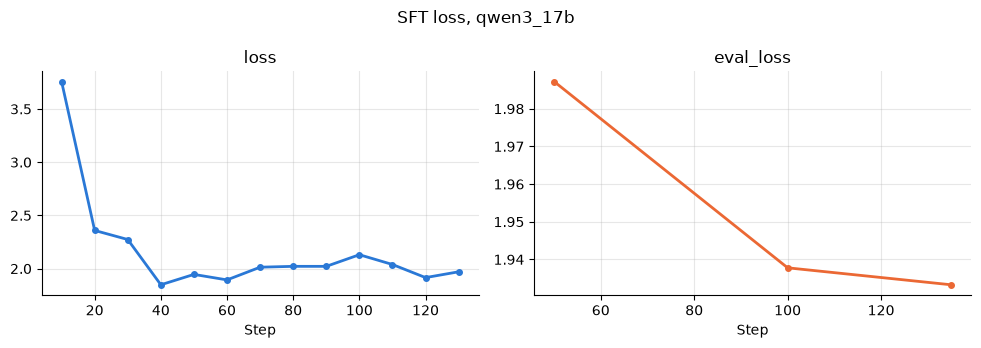

In [7]:
plot_log(f'results/{MODEL_KEY}_sft_log.csv', ['loss', 'eval_loss'], f'SFT loss, {MODEL_KEY}')

### 4. DPO preference pairs
For each DPO question the SFT model writes 4 summaries: 1 greedy, the way it answers at test time, and 3 sampled (temperature 0.9). The greedy one is there because the SFT model sometimes gets stuck repeating itself with greedy decoding, and sampled answers almost never do, so without it DPO would never see that mistake. Each summary is scored as 0.5 x faithfulness (HHEM: is it supported by the chunks?) + 0.5 x ROUGE-L (is it close to the human summary?), times the share of distinct 4-grams (pushes repetition loops to the bottom), times the length ratio to the human summary (shorter / longer word count, so DPO does not learn that shorter is always better). Best = chosen, worst = rejected. Pairs with a score gap under 0.1 are dropped because they teach little. About 1 to 1.5 hours on a T4, and the loop can resume.

In [8]:
from tqdm.auto import tqdm
done = st.done_keys(PAIRS_PATH)
todo = [e for e in dpo_examples if (e['meeting_id'], e['query']) not in done]
print(len(done), 'questions done,', len(todo), 'to go')
if todo:
    llm = st.LLM(MODEL_ID, adapter=SFT_DIR, load_4bit=LOAD_4BIT)
    faith = st.Faithfulness()
    with st.Timer('dpo_candidates', MODEL_KEY) as timer:
        timer.flops_per_token = st.flops_per_token(MODEL_KEY, 'answer')
        try:
            for ex in tqdm(todo):
                m = meetings_by_id[ex['meeting_id']]
                # the same retrieved chunks as rag mode, cut to fit MAX_LEN with the answer so DPO never cuts an answer
                budget = MAX_LEN - DPO_MAX_NEW_TOKENS - PROMPT_RESERVE
                ctx = st.format_docs(st.fit_docs(tok, st.ranked_docs(m, ex, retriever, k=K), budget))
                prompt = st.summary_messages(ctx, ex['query'])
                # DPO_GREEDY answers like at test time, the rest sampled
                cands = [llm.chat(prompt, max_new_tokens=DPO_MAX_NEW_TOKENS) for _ in range(DPO_GREEDY)]
                sampled = llm.chat(prompt, temperature=DPO_TEMPERATURE, n=DPO_CANDIDATES - DPO_GREEDY, max_new_tokens=DPO_MAX_NEW_TOKENS)
                cands += sampled if isinstance(sampled, list) else [sampled]
                scores, f, r = st.score_candidates(cands, ctx, ex['answer'], faith)
                st.append_jsonl(PAIRS_PATH, {'meeting_id': ex['meeting_id'], 'query': ex['query'], 'prompt': prompt,
                                             'candidates': cands, 'greedy': DPO_GREEDY, 'scores': scores, 'faith': f, 'rougeL': r})
        finally:
            timer.tokens = llm.tokens_in + llm.tokens_out
    llm.unload(); del faith; st.free_memory()

300 questions done, 0 to go


### 5. DPO training
First the saved candidates become best vs worst pairs, then the SFT adapter keeps training with DPO. TRL keeps a frozen copy of the SFT adapter as the reference model, so only one copy of the base model is in memory. beta = 0.1, learning rate 5e-5, 1 epoch (5e-6 barely changed the adapter in the first run). The SFT loss on the chosen summary is added to the DPO loss (RPO), which keeps the model close to the good summaries; without it the second run drifted to answers half the human length. Check that chosen and rejected lengths are similar: if chosen is much longer, DPO may just learn to write longer. After a disconnect, run this section again and training continues from the last checkpoint.

In [9]:
cand_rows = st.read_jsonl(PAIRS_PATH) if os.path.exists(PAIRS_PATH) else []
left = len(dpo_examples) - len(cand_rows)
assert left <= 0, f'{left} DPO questions still have no candidates, finish section 4 first'
# rewards are recomputed from the saved faithfulness and ROUGE-L, so a change to the reward needs no new candidates
answers = {(e['meeting_id'], e['query']): e['answer'] for e in dpo_examples}
for r in cand_rows:
    r['scores'] = st.rescore_candidates(r, answers[(r['meeting_id'], r['query'])])
pairs = [p for p in (st.best_worst_pair(r) for r in cand_rows) if p]
words = lambda msgs: len(msgs[0]['content'].split())
print(f'{len(pairs)} pairs kept out of {len(cand_rows)} questions')
print('Average words, chosen:', round(sum(words(p['chosen']) for p in pairs) / len(pairs)),
      '| rejected:', round(sum(words(p['rejected']) for p in pairs) / len(pairs)))
loops = lambda side: sum(st.distinct_share(p[side][0]['content']) < LOOP_BELOW for p in pairs)
print('Repetition loops, chosen:', loops('chosen'), '| rejected:', loops('rejected'))
dpo_data = Dataset.from_list([{k: p[k] for k in ['prompt', 'chosen', 'rejected']} for p in pairs]).train_test_split(0.1, seed=42)
dpo_data

282 pairs kept out of 300 questions
Average words, chosen: 62 | rejected: 65
Repetition loops, chosen: 4 | rejected: 42


DatasetDict({
    train: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 253
    })
    test: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 29
    })
})

In [10]:
if st.has_adapter(DPO_DIR) and not RETRAIN:
    print('DPO adapter found in', DPO_DIR, 'so training is skipped. Set RETRAIN = True to train again.')
else:
    ckpt = last_checkpoint(DPO_DIR + '_ckpt')
    print('DPO starts from', ckpt or 'the beginning')
    model = load_4bit(MODEL_ID)
    model = PeftModel.from_pretrained(model, SFT_DIR, is_trainable=True)
    # DPO holds the hyperparameters from config.py
    dpo_args = DPOConfig(output_dir=DPO_DIR + '_ckpt', max_length=MAX_LEN, bf16=use_bf16, fp16=not use_bf16,
                         eval_strategy='steps', report_to='none', **DPO)
    trainer = DPOTrainer(model=model, args=dpo_args, train_dataset=dpo_data['train'], eval_dataset=dpo_data['test'],
                         processing_class=tok)
    with st.Timer('dpo_train', MODEL_KEY) as timer:
        timer.flops_per_token = st.flops_per_token(MODEL_KEY, 'dpo')
        trainer.train(resume_from_checkpoint=ckpt)
        done = 1 - (int(ckpt.rsplit('-', 1)[1]) if ckpt else 0) / trainer.state.max_steps   # share trained in this session
        timer.tokens = st.train_tokens(trainer.train_dataset, DPO['num_train_epochs']) * done
    trainer.save_model(DPO_DIR)
    pd.DataFrame(trainer.state.log_history).to_csv(f'results/{MODEL_KEY}_dpo_log.csv', index=False)
    del trainer, model; st.free_memory()

DPO starts from the beginning


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

~/smalltalk_env/lib/python3.12/site-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


~/smalltalk_env/lib/python3.12/site-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Tokenizing train dataset:   0%|          | 0/253 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/253 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/29 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/29 [00:00<?, ? examples/s]

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
20,1.577015,1.493108,1.592304,665014.000000,1.109569,1.200777,0.768108,0.207598,-0.020247,0.724138,0.227846,-56.688536,-80.776111
32,1.536102,1.492903,1.580100,1048684.000000,1.088941,1.182599,0.767292,0.198446,-0.042150,0.758621,0.240596,-56.780058,-80.995142


dpo_train (qwen3_17b): 25.6 min, peak GPU memory 2.8 GB, 1,048,684.0 tokens, about 14,262 TFLOPs


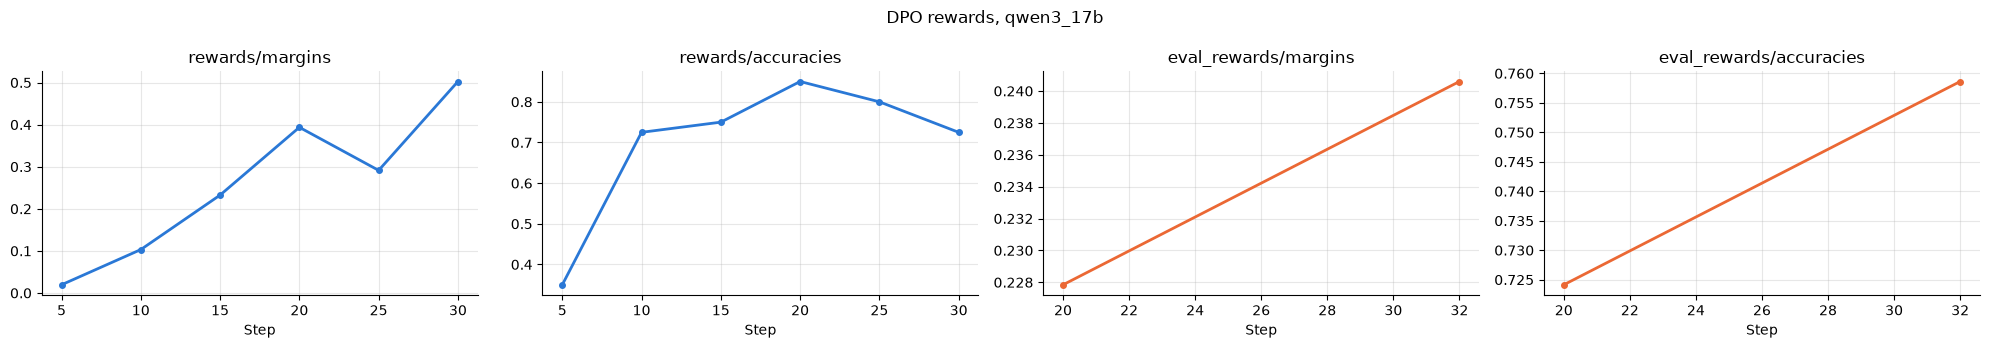

In [11]:
# margins going up and accuracy above 0.5 means the model prefers the chosen summaries
plot_log(f'results/{MODEL_KEY}_dpo_log.csv', ['rewards/margins', 'rewards/accuracies', 'eval_rewards/margins', 'eval_rewards/accuracies'],
         f'DPO rewards, {MODEL_KEY}')